In [1]:
import scanpy as sc
import numpy as np 
import matplotlib.pyplot as plt
import pandas as pd
import scvelo as scv
import anndata as ad
import pickle as pkl
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from scipy.stats import binned_statistic_2d
from sklearn.neighbors import NearestNeighbors
import scipy.sparse as sp
from sklearn.preprocessing import LabelEncoder
from sklearn.decomposition import TruncatedSVD

from sklearn.decomposition import PCA
import umap
from itertools import product

python_data_dir = r"C:\Users\Nikla\Documents\MoBi_Master_FS.3\Internship AG Höfer\DynaVelo_testing\data"

In [56]:
velo_gene_df = pd.read_csv(rf"{python_data_dir}\pmtr_peak_sub\chrom_velo_gene_subset.csv", index_col=0, header=0)
velo_genes = velo_gene_df.index.tolist()

#velo_genes = ['Abcb4', 'Adgrg1', 'Atp1b2', 'Ermap', 'Gstm5', 'Hspd1', 'Ifrd2', 'Iqgap2', 'Klf1', 'Lman2', 'Mki67', 'Mt1', 'Ptprc']

In [57]:
adata_atac_all_lin = sc.read_h5ad(rf"{python_data_dir}\pmtr_peak_sub\atac.h5ad")
adata_rna_all_lin = sc.read_h5ad(rf"{python_data_dir}\pmtr_peak_sub\rna.h5ad")

adata_atac_all_lin.layers["counts"] = adata_atac_all_lin.X.copy()
sc.pp.normalize_total(adata_atac_all_lin, target_sum=np.median(adata_atac_all_lin.X.sum(1)))
sc.pp.log1p(adata_atac_all_lin)
# sc.pp.pca(adata_rna_all_lin)
# sc.pp.pca(adata_atac_all_lin)

myeloid_cells = adata_rna_all_lin.obs_names.values[adata_rna_all_lin.obsm["X_pca"][:,1]<=1]  # filter to only myeloid lineage
adata_atac = adata_atac_all_lin#[myeloid_cells,:]
adata_rna = adata_rna_all_lin#[myeloid_cells,:]

adata_rna.var["highly_variable"] = True
adata_atac.var["highly_variable"] = True

# adata_rna.var["highly_variable"] = adata_rna.var_names.isin(velo_genes)
# adata_atac.var["highly_variable"] = adata_atac.var_names.isin(velo_genes)

atac_df = pd.DataFrame(data=adata_atac.X, index=adata_atac.obs_names.values, columns=adata_atac.var_names.values)
rna_df = pd.DataFrame(data=adata_rna.X.toarray(), index=adata_rna.obs_names.values, columns=adata_rna.var_names.values)

## kNN 50 Smoothing of Signals
To calculate chromatin potential, we first smoothed DORC scores (chromatin space) and corresponding gene expression (RNA space) over a k-nearest neighbor graph (k-NN, k=50), calculated using normalized ATAC topics from cisTopic.

In [58]:
def minmax_cols(df):
    mn, mx = df.min(axis=0), df.max(axis=0)
    rng = (mx - mn).replace(0, np.nan)   # constant columns would divide by zero
    return ((df - mn) / rng).fillna(0)

In [59]:
assert (adata_atac.obs_names == adata_rna.obs_names).all()

def run_lsi(counts, n_comps=30, scale=1e4):
    X = sp.csr_matrix(counts, dtype=np.float32)
    tf = sp.diags(1 / np.maximum(np.asarray(X.sum(1)).ravel(), 1)) @ X      # term frequency per cell
    df = np.asarray((X > 0).sum(0)).ravel()                                  # cells with each peak open
    idf = np.log1p(X.shape[0] / (1 + df))                                    # inverse document frequency
    X_t = (tf @ sp.diags(idf)).tocsr()
    X_t.data = np.log1p(X_t.data * scale)
    svd = TruncatedSVD(n_components=n_comps + 1, algorithm="arpack", random_state=0)
    Z = svd.fit_transform(X_t)
    return Z[:, 1:]                                                          # drop depth-driven component 1

adata_atac.obsm["X_lsi"] = run_lsi(adata_atac.layers["counts"], n_comps=30)
sc.pp.pca(adata_rna, n_comps=30)

rna_pc  = adata_rna.obsm["X_pca"][:, :30]
atac_pc = adata_atac.obsm["X_lsi"]

# # joint neighborhood embedding
# sc.pp.pca(adata_atac, n_comps=30)
# sc.pp.pca(adata_rna, n_comps=30)

# rna_pc  = adata_rna.obsm["X_pca"][:, :30]
# atac_pc = adata_atac.obsm["X_pca"][:, :30]

emb = np.hstack([rna_pc / rna_pc.std(), atac_pc / atac_pc.std()])  # equalize modality , I also tried just emb = atac_pc, but this was degenerate

def knn_smoother(emb, k=50):
    idx = NearestNeighbors(n_neighbors=k).fit(emb).kneighbors(emb, return_distance=False)
    n = emb.shape[0]
    return sp.csr_matrix((np.full(n * k, 1 / k), (np.repeat(np.arange(n), k), idx.ravel())), shape=(n, n))

S = knn_smoother(emb, k=50)

def smooth(df):
    return pd.DataFrame(S @ df.to_numpy(float), index=df.index, columns=df.columns)

atac_velo = smooth(atac_df.loc[:, velo_genes])
rna_velo  = smooth(rna_df.loc[:, velo_genes])

atac_velo = minmax_cols(atac_velo)
rna_velo  = minmax_cols(rna_velo)

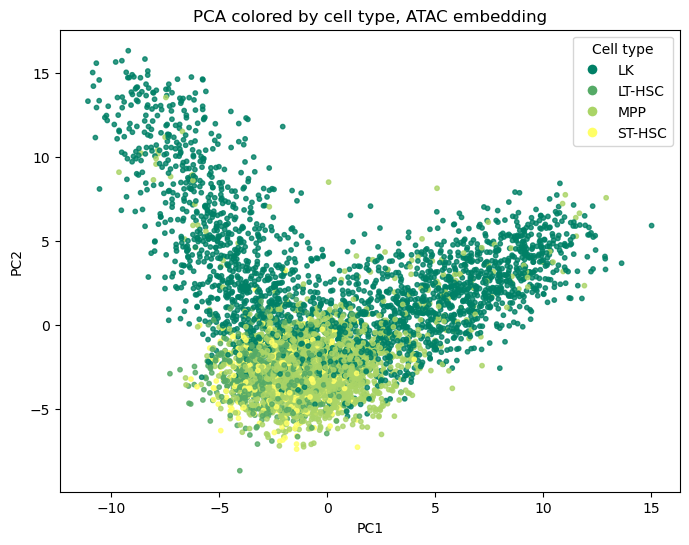

In [60]:
from matplotlib.lines import Line2D
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
le.fit(["LT-HSC", "ST-HSC", "MPP", "LK"])

colors = le.transform(adata_rna.obs["celltype"].values)
cmap = plt.get_cmap("summer", len(le.classes_))

plt.figure(figsize=(8, 6))
plt.scatter(
    adata_atac.obsm["X_lsi"][:, 0],
    adata_atac.obsm["X_lsi"][:, 1],
    c=colors,
    cmap=cmap,
    s=10,
    alpha=0.8
)

# Create a legend
handles = [
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        markerfacecolor=cmap(i),
        markersize=8,
        label=celltype
    )
    for i, celltype in enumerate(le.classes_)
]

plt.legend(handles=handles, title="Cell type")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA colored by cell type, ATAC embedding")
plt.show()

## kNN 10 Assignment of ATAC to RNA
Find the 10 RNA profiles with the highest correlation to the current ATAC cell and compute their average as the predicted future state of the ATAC. The difference between the two points results in a velocity / chromatin potential.

Built together with Claude, to find a good compromise between the description in the paper and the implementation from SCARlink: https://github.com/snehamitra/SCARlink/blob/main/notebooks/chromatin_potential.ipynb; https://claude.ai/chat/68bcc85f-9655-47c8-801a-4c7dfbff5c9f

In [61]:
# ---- settings (paper values) ----
K_MATCH = 10          # cross-modal kNN
K_ARROW = 15          # arrow smoothing in low-dim space
USE_UMAP = True       # paper visualises on UMAP; set False to use ATAC PC1/PC2

A = atac_velo.to_numpy(float)   # smoothed, min-max scaled chromatin profiles (cells x genes)
R = rna_velo.to_numpy(float)    # smoothed, min-max scaled RNA profiles       (cells x genes)

def zrow(M):
    sd = M.std(1, keepdims=True)
    sd[sd == 0] = 1.0
    return (M - M.mean(1, keepdims=True)) / sd

# Central matching step!! 
# Pearson correlation of every ATAC profile i with every RNA profile j (over genes)
corr = zrow(A) @ zrow(R).T / A.shape[1]
nn = np.argpartition(-corr, K_MATCH - 1, axis=1)[:, :K_MATCH]   # top-10 RNA matches per ATAC cell

# chromatin-space embedding in which positions are averaged and arrows drawn
#atac_pc = adata_atac.obsm["X_pca"][:, :30]
atac_pc = adata_atac.obsm["X_lsi"]
E = umap.UMAP(n_neighbors=30, min_dist=0.3, random_state=0).fit_transform(atac_pc)

# arrow = position of current cell - mean position of matched cells
# The order here is not SUPER clear but: "We then calculated the distance (Di, j) between the Catac, i and the average of Crna, j in chromatin space"
arrows = E[nn].mean(axis=1) - E
arrows /= np.percentile(np.linalg.norm(arrows, axis=1), 99) # length normalisation

# smooth arrows over the 15 nearest neighbours in the low-dim space
idx = NearestNeighbors(n_neighbors=K_ARROW).fit(E).kneighbors(E, return_distance=False)
arrows_s = arrows[idx].mean(axis=1)

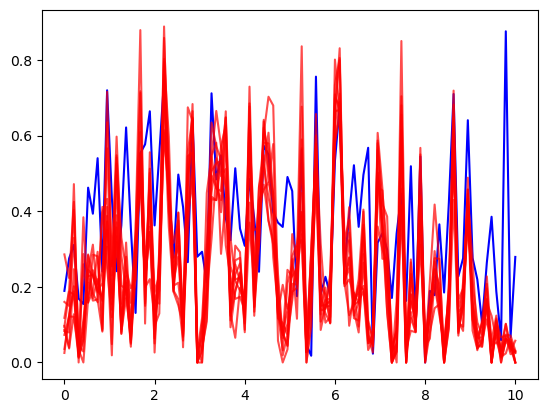

In [62]:
plt.plot(np.linspace(0,10, len(velo_genes)), atac_velo.loc["AAACAGCCACTAAGTT",:], c="blue")
for i in range(10):
    plt.plot(np.linspace(0,10, len(velo_genes)), rna_velo.iloc[nn[0,i],:], c="red", alpha=0.7)

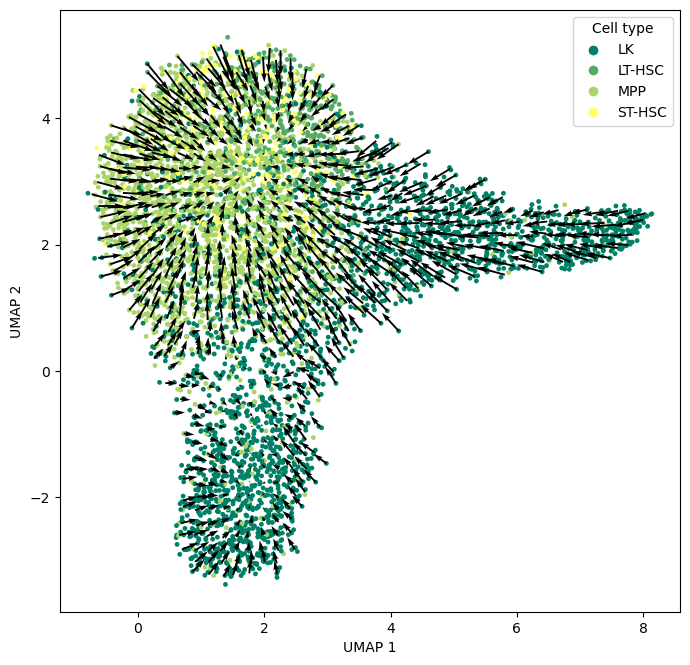

In [63]:
# Plotting of the resulting vectors in umap
N_BINS = 40
MIN_CELLS = 1          # drop sparse grid squares
ARROW_SCALE = 0.8      # >1 makes arrows longer for visibility

x, y = E[:, 0], E[:, 1]
u, v = arrows_s[:, 0], arrows_s[:, 1]

xe = np.linspace(x.min(), x.max(), N_BINS + 1)
ye = np.linspace(y.min(), y.max(), N_BINS + 1)

def bstat(vals, stat):
    return binned_statistic_2d(x, y, vals, stat, bins=[xe, ye]).statistic

cnt = bstat(None, "count")
X, Y = bstat(x, "mean"), bstat(y, "mean")      # arrow origin = mean cell position in the square
U, V = bstat(u, "mean"), bstat(v, "mean")      # average arrow of all cells in the square

keep = (cnt >= MIN_CELLS) & np.isfinite(U) & np.isfinite(V)
length = np.hypot(U, V)

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(x, y, s=12, c=colors, cmap=cmap, alpha=1, linewidths=0, zorder=0)

q = ax.quiver(
    X[keep], Y[keep], U[keep] * ARROW_SCALE, V[keep] * ARROW_SCALE, #length[keep],
    angles="xy", scale_units="xy", scale=1,
    width=0.003, zorder=2, alpha=1, #cmap="inferno",
)

handles = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor=cmap(i),
           markersize=8, label=celltype)
    for i, celltype in enumerate(le.classes_)
]
ax.legend(handles=handles, title="Cell type")

#plt.colorbar(q, ax=ax, shrink=0.4, label="chromatin potential (arrow length)")
ax.set_xlabel("UMAP 1" if USE_UMAP else "chromatin PC1")
ax.set_ylabel("UMAP 2" if USE_UMAP else "chromatin PC2")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

Curiously, when using E - E[avg] with the incorrect filtering of velocity genes by using a positive lag (RNA signal ahead of ATAC), results in the best results. This double mistake cancels out and gives quite good velocities. When using the branch method to find good velocity genes, or simply correcting the lag cutoff filter on the genes, the result is far more noisy and doesn't show the correct results... This might be related to the fact, that the positive lag genes show much larger lags and are more usable for the velocity computation.

When not filtering the genes at all by lag (as currently) the signal of the positive lag overpowers the other signal and it pretty much looks like the direction is just completely wrong...

One thing I am thinking about is not using only monotonically increasing and decreasing genes, but ones with a lag between the maxima or something similar. Just to get a stronger lag signal!!!

Next I want to rerun the gene filtering analysis for the other development branch also and use more velocity genes!

In [165]:
A = atac_velo.to_numpy(float)
R = rna_velo.to_numpy(float)

def center_cols(M): 
    return M - M.mean(axis=0)

def zrow(M):        
    return (M - M.mean(1, keepdims=True)) / M.std(1, keepdims=True)

Az = zrow(center_cols(A))
Rz = zrow(center_cols(R))
corr = Az @ Rz.T / A.shape[1]
nn = np.argpartition(-corr, 10, axis=1)[:,:10]  # selects ten closest based on correlation

E = adata_atac.obsm["X_pca"][:, :2]

arrows = E - E[nn].mean(axis=1)
arrows /= np.percentile(np.linalg.norm(arrows, axis=1), 99)  # normalization

# smooth over 15 kNN in the embedding
idx = NearestNeighbors(n_neighbors=15).fit(E).kneighbors(E, return_distance=False)
arrows_s = arrows[idx].mean(axis=1)

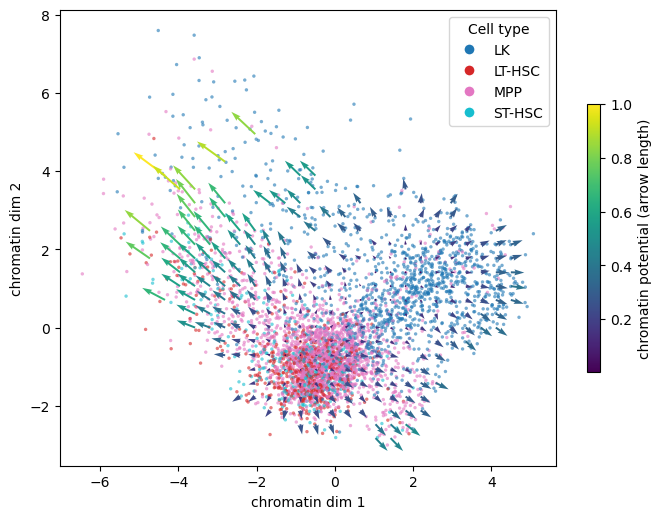

In [183]:
x, y = E[:, 0], E[:, 1]
u, v = arrows_s[:, 0], arrows_s[:, 1]

nb = 30
xe = np.linspace(x.min(), x.max(), nb + 1)
ye = np.linspace(y.min(), y.max(), nb + 1)
cx, cy = (xe[:-1] + xe[1:]) / 2, (ye[:-1] + ye[1:]) / 2
CX, CY = np.meshgrid(cx, cy, indexing="ij")        # [x_bin, y_bin], same as binned_statistic_2d

cnt = binned_statistic_2d(x, y, None, "count", bins=[xe, ye]).statistic
U = binned_statistic_2d(x, y, u, "mean", bins=[xe, ye]).statistic
V = binned_statistic_2d(x, y, v, "mean", bins=[xe, ye]).statistic

keep = (cnt >= 3) & np.isfinite(U) & np.isfinite(V)   # drop empty / sparse bins
length = np.hypot(U, V)

fig, ax = plt.subplots(figsize=(7, 7))
scatter = ax.scatter(x, y, s=6, c=colors, cmap="tab10", alpha=0.6, linewidths=0, zorder=0)

q = ax.quiver(
    CX[keep], CY[keep], U[keep], V[keep], length[keep],
    angles="xy", scale_units="xy", scale=1,   # true embedding units
    width=0.004, cmap="viridis", zorder=2,
)

handles = [
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        markerfacecolor=cmap(i),
        markersize=8,
        label=celltype
    )
    for i, celltype in enumerate(le.classes_)
]

plt.legend(handles=handles, title="Cell type")

plt.colorbar(q, ax=ax, shrink=0.4, label="chromatin potential (arrow length)")
ax.set_xlabel("chromatin dim 1")
ax.set_ylabel("chromatin dim 2")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

## Old approach

In [ ]:
A = atac_velo.values   # (n_cells, n_genes)
R = rna_velo.values     # (n_cells, n_genes)

A_std = (A - A.mean(axis=1, keepdims=True)) / A.std(axis=1, keepdims=True)
R_std = (R - R.mean(axis=1, keepdims=True)) / R.std(axis=1, keepdims=True)

corrs_axr = pd.DataFrame(
    A_std @ R_std.T / A.shape[1],
    index=atac_velo.index,  # atac cells
    columns=rna_velo.index,  # rna cells 
)
nns = {}

for cell in corrs_axr.index: 
    pot_partners = corrs_axr.loc[cell, :]
    nn10s = pot_partners.sort_values(ascending=False).index[:10]
    nns[cell] = nn10s
rna_avg = pd.DataFrame(index=nns.keys(), columns=rna_velo.columns.tolist())
# contains the average profile most closely associated with each cell's ATAC profile
for key, rna_partners in nns.items(): 
    rna_avg.loc[key,:] = np.mean(rna_velo.loc[rna_partners,:].values, axis=0)
rna_avg = rna_avg.loc[atac_velo.index, atac_velo.columns] 
delta = rna_avg.astype(float) - atac_velo.astype(float)